In [164]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.linear_model import LinearRegression,SGDRegressor
from sklearn .metrics import mean_squared_error,mean_absolute_error,r2_score


In [165]:
df=pd.read_csv("Car_Price_Prediction.csv")
df.sample(7)

,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price
527,BMW,Model D,2009,2.2,105703,Electric,Automatic,28398.167386
104,Toyota,Model E,2012,4.0,10564,Petrol,Automatic,36806.291946
247,BMW,Model A,2002,2.6,90045,Petrol,Manual,18468.303488
451,Audi,Model A,2011,2.4,199416,Electric,Manual,18747.469660
376,Toyota,Model D,2013,4.0,99280,Electric,Automatic,30928.595088
205,Ford,Model B,2006,3.8,172438,Electric,Automatic,18600.905195
269,BMW,Model C,2016,1.5,59622,Electric,Manual,27270.822830


In [166]:
df.columns

Index(['Make', 'Model', 'Year', 'Engine Size', 'Mileage', 'Fuel Type',
       'Transmission', 'Price'],
      dtype='object')

In [167]:
df.shape

(1000, 8)

In [168]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Make          1000 non-null   object 
 1   Model         1000 non-null   object 
 2   Year          1000 non-null   int64  
 3   Engine Size   1000 non-null   float64
 4   Mileage       1000 non-null   int64  
 5   Fuel Type     1000 non-null   object 
 6   Transmission  1000 non-null   object 
 7   Price         1000 non-null   float64
dtypes: float64(2), int64(2), object(4)
memory usage: 62.6+ KB


In [169]:
df.isnull().sum()

Make            0
Model           0
Year            0
Engine Size     0
Mileage         0
Fuel Type       0
Transmission    0
Price           0
dtype: int64

In [170]:
df.duplicated().sum()

0

In [134]:
df[['Year','Engine Size','Mileage','Price']].describe().T

,count,mean,std,min,25%,50%,75%,max
Year,1000.0,2010.68800,6.288577,2000.000000,2005.00000,2011.000000,2016.000000,2021.000000
Engine Size,1000.0,2.79830,1.024137,1.000000,1.90000,2.800000,3.700000,4.500000
Mileage,1000.0,97192.48700,59447.315760,56.000000,44768.75000,94411.500000,148977.750000,199867.000000
Price,1000.0,25136.61553,5181.401368,6704.953524,21587.87837,25189.325247,28806.368974,41780.504635


In [171]:
categorical_cols=df.select_dtypes(include='object').columns
df[categorical_cols].describe().T

,count,unique,top,freq
Make,1000,5,Ford,225
Model,1000,5,Model B,212
Fuel Type,1000,3,Diesel,344
Transmission,1000,2,Manual,511


In [172]:
for col in categorical_cols:
    print(f"\n{col}")
    display(df[col].value_counts())


Make


Make
Ford      225
Audi      212
Honda     198
Toyota    187
BMW       178
Name: count, dtype: int64


Model


Model
Model B    212
Model C    205
Model A    202
Model D    197
Model E    184
Name: count, dtype: int64


Fuel Type


Fuel Type
Diesel      344
Petrol      331
Electric    325
Name: count, dtype: int64


Transmission


Transmission
Manual       511
Automatic    489
Name: count, dtype: int64

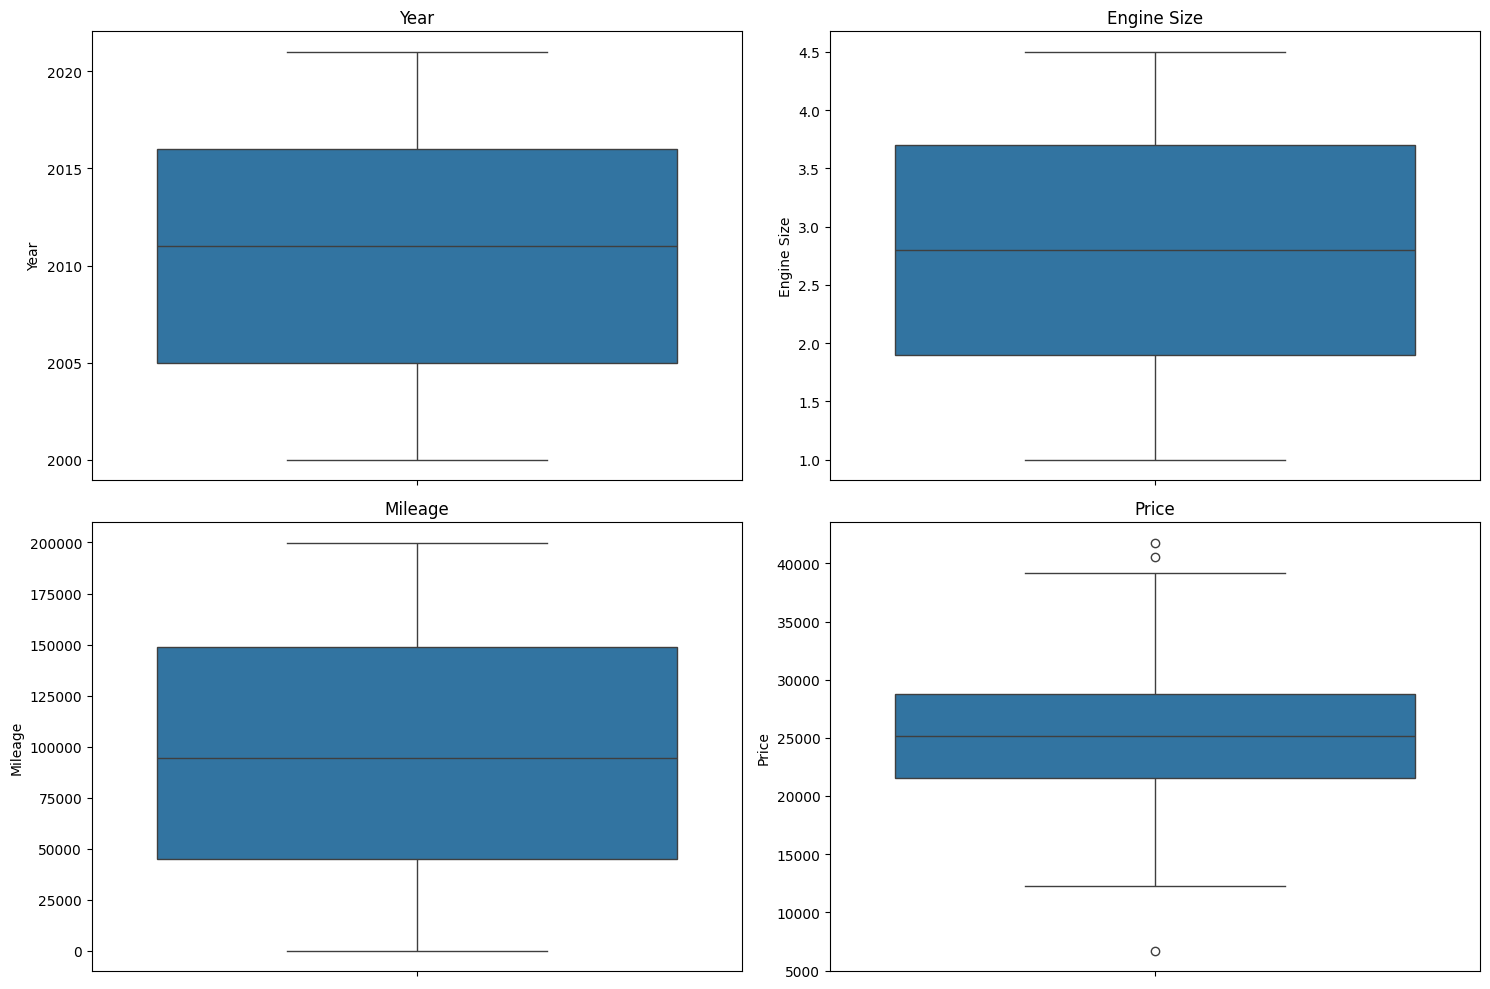

In [173]:
num_cols=['Year','Engine Size','Mileage','Price']
plt.figure(figsize=(15,10))

for index,col in enumerate(num_cols,1):
    plt.subplot(2,2,index)
    sns.boxplot(data=df,y=col)
    plt.title(col)

plt.tight_layout()
plt.show()

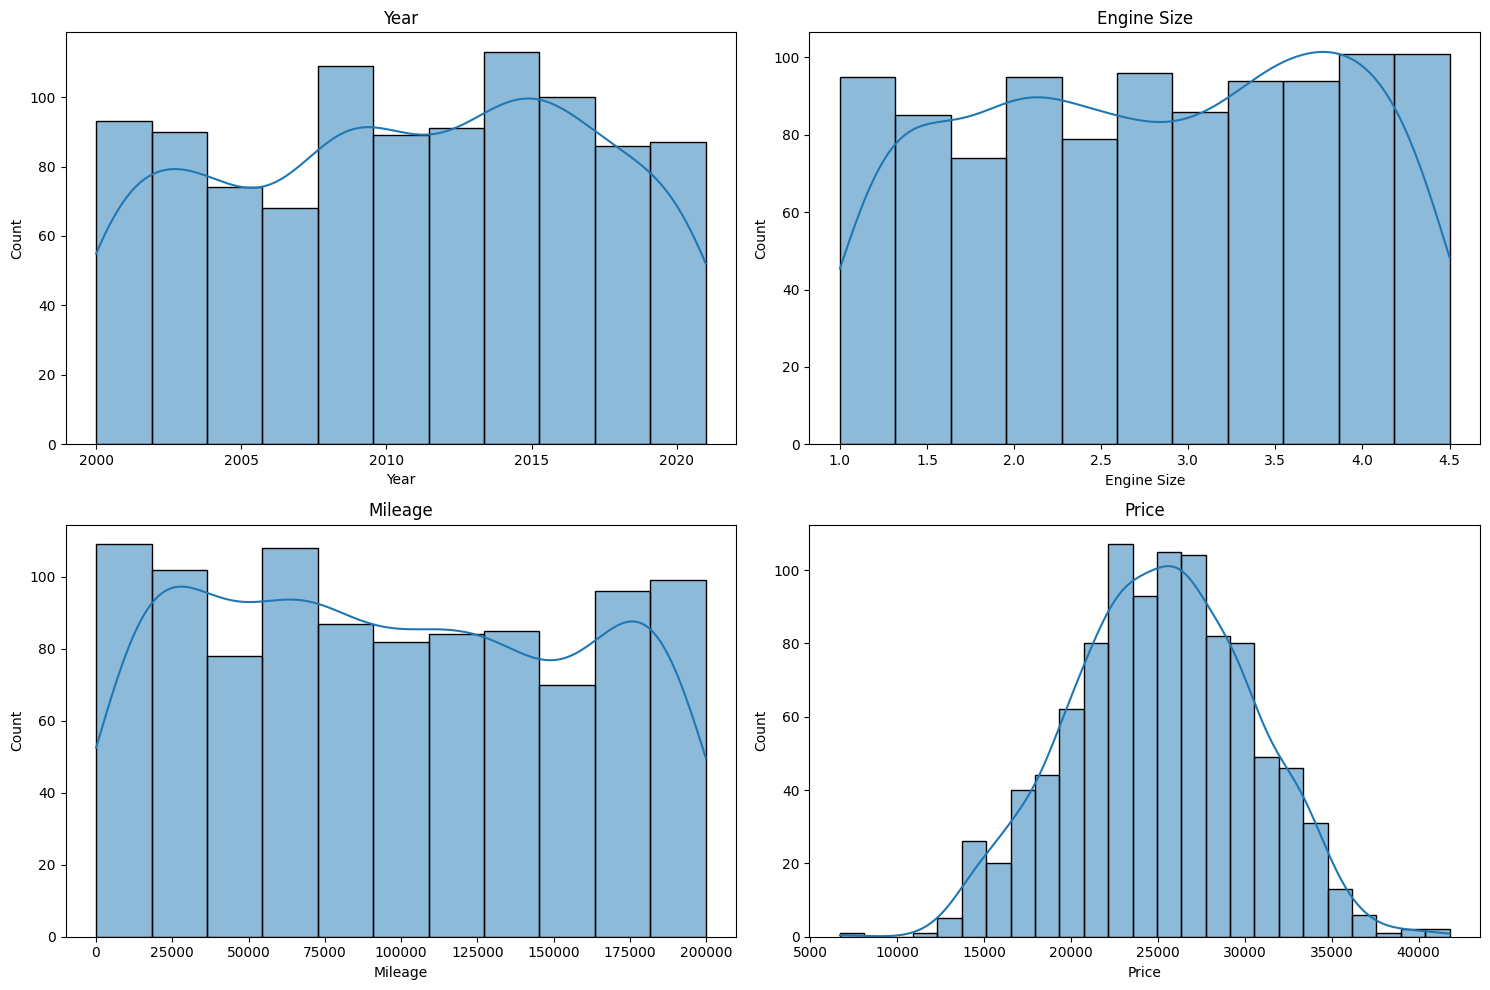

In [174]:
plt.figure(figsize=(15,10))

for index,col in enumerate(num_cols,1):
    plt.subplot(2,2,index)
    sns.histplot(data=df,x=col,kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

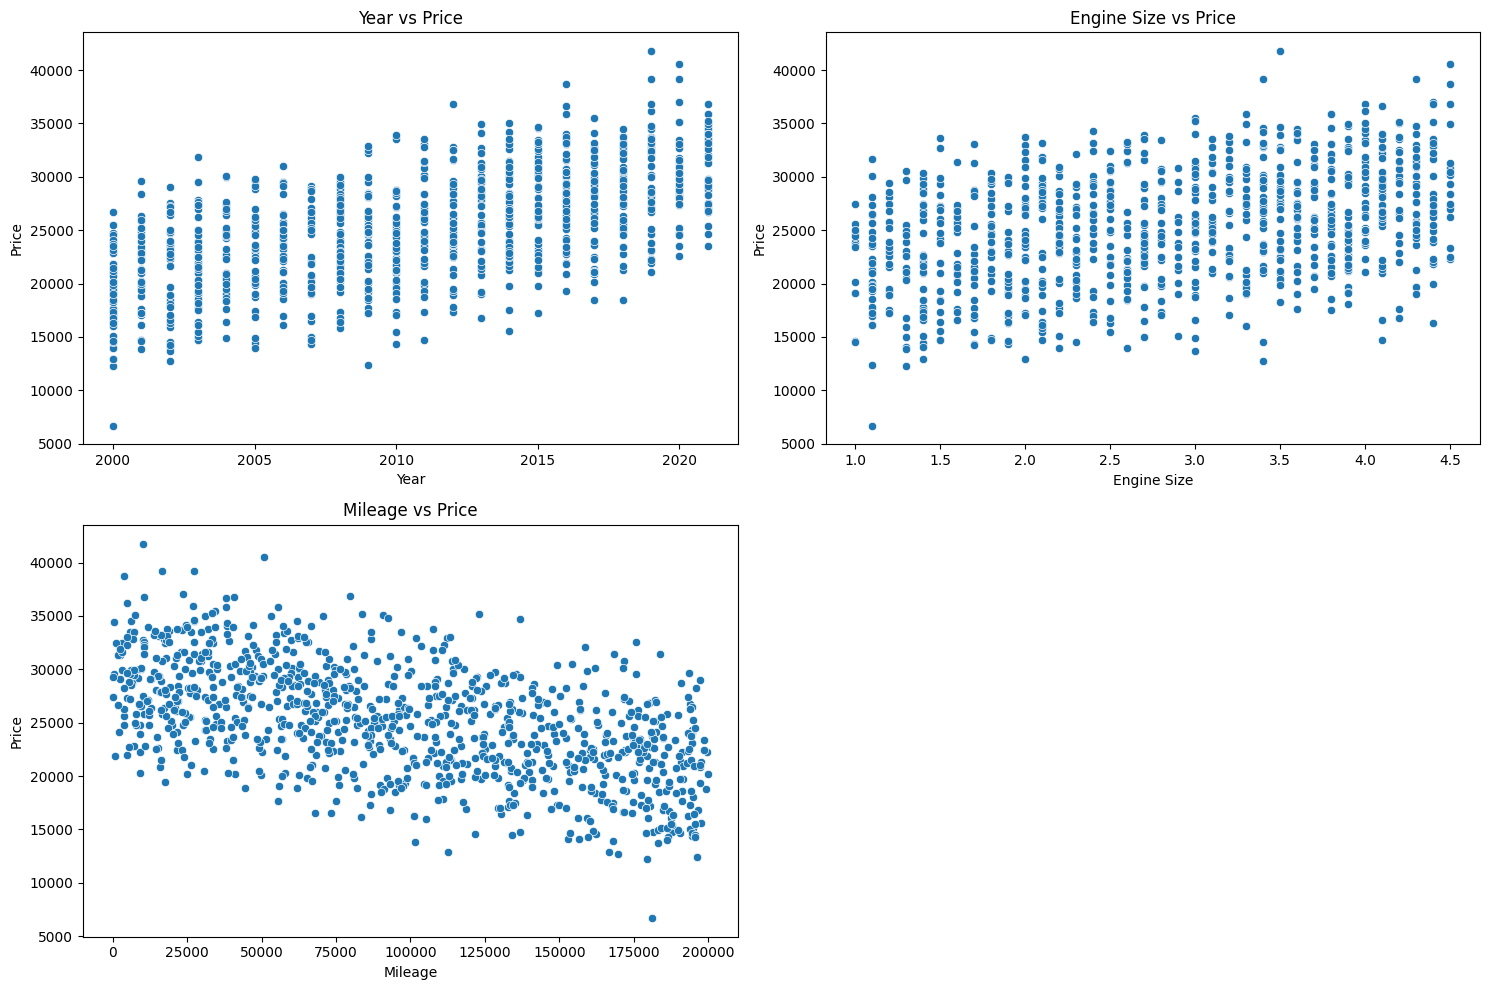

In [175]:
features=['Year','Engine Size','Mileage']
plt.figure(figsize=(15,10))

for index,col in enumerate(features,1):
    plt.subplot(2,2,index)
    sns.scatterplot(data=df,x=col,y='Price')
    plt.title(f'{col} vs Price')

plt.tight_layout()
plt.show()

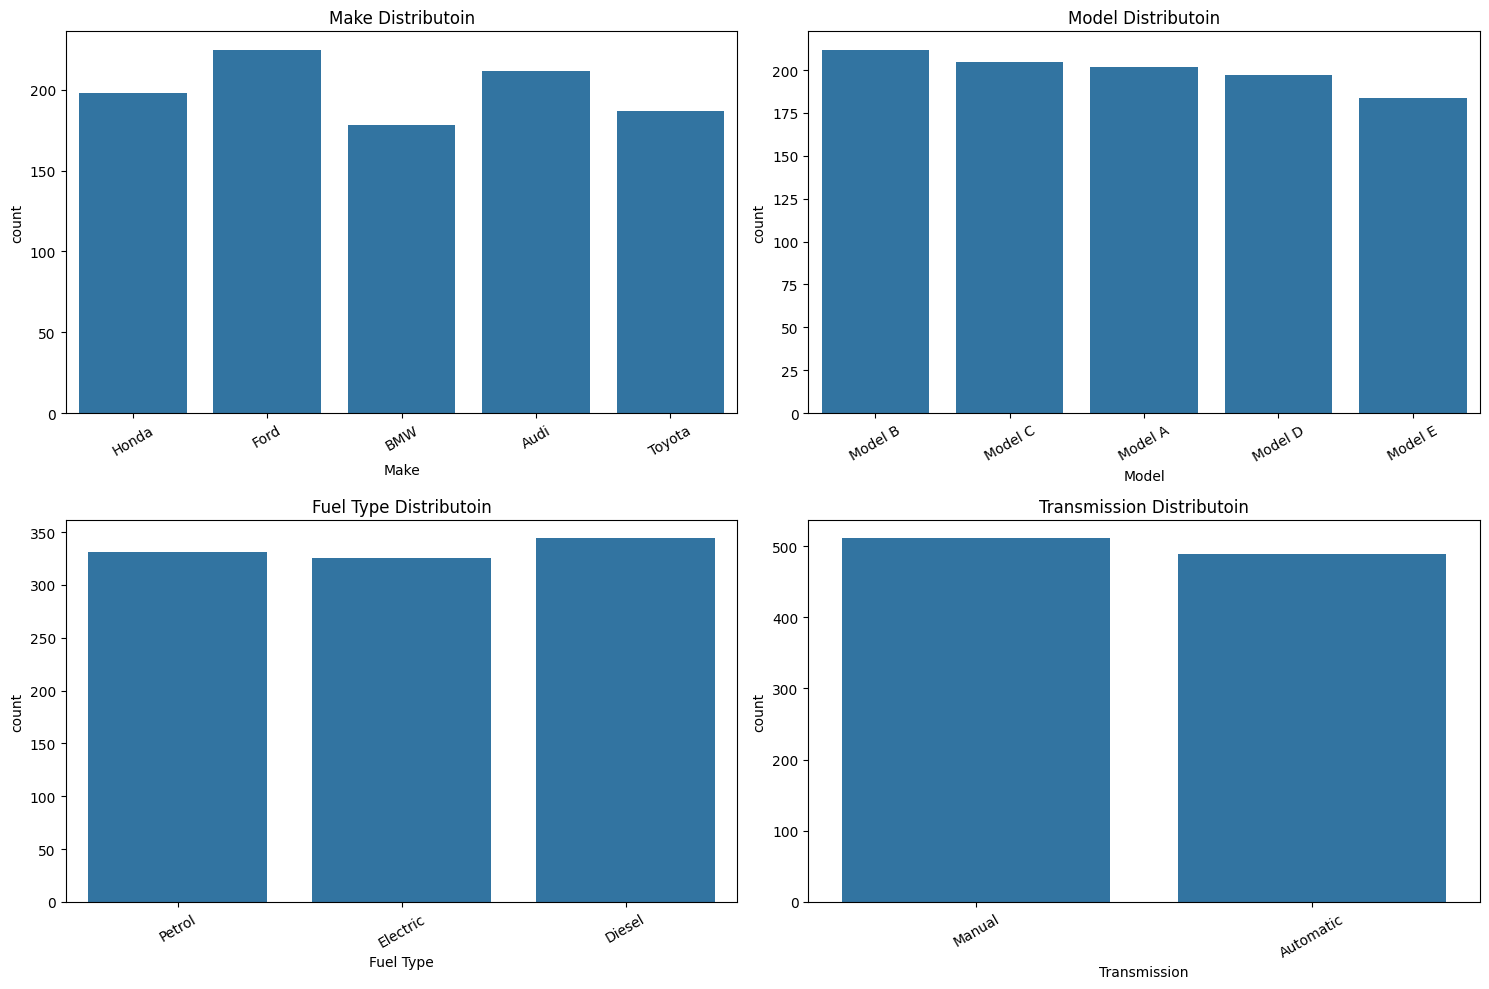

In [176]:
plt.figure(figsize=(15,10))

for index,col in enumerate(categorical_cols,1):
    plt.subplot(2,2,index)
    sns.countplot(data=df,x=col)
    plt.title(f'{col} Distributoin')
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

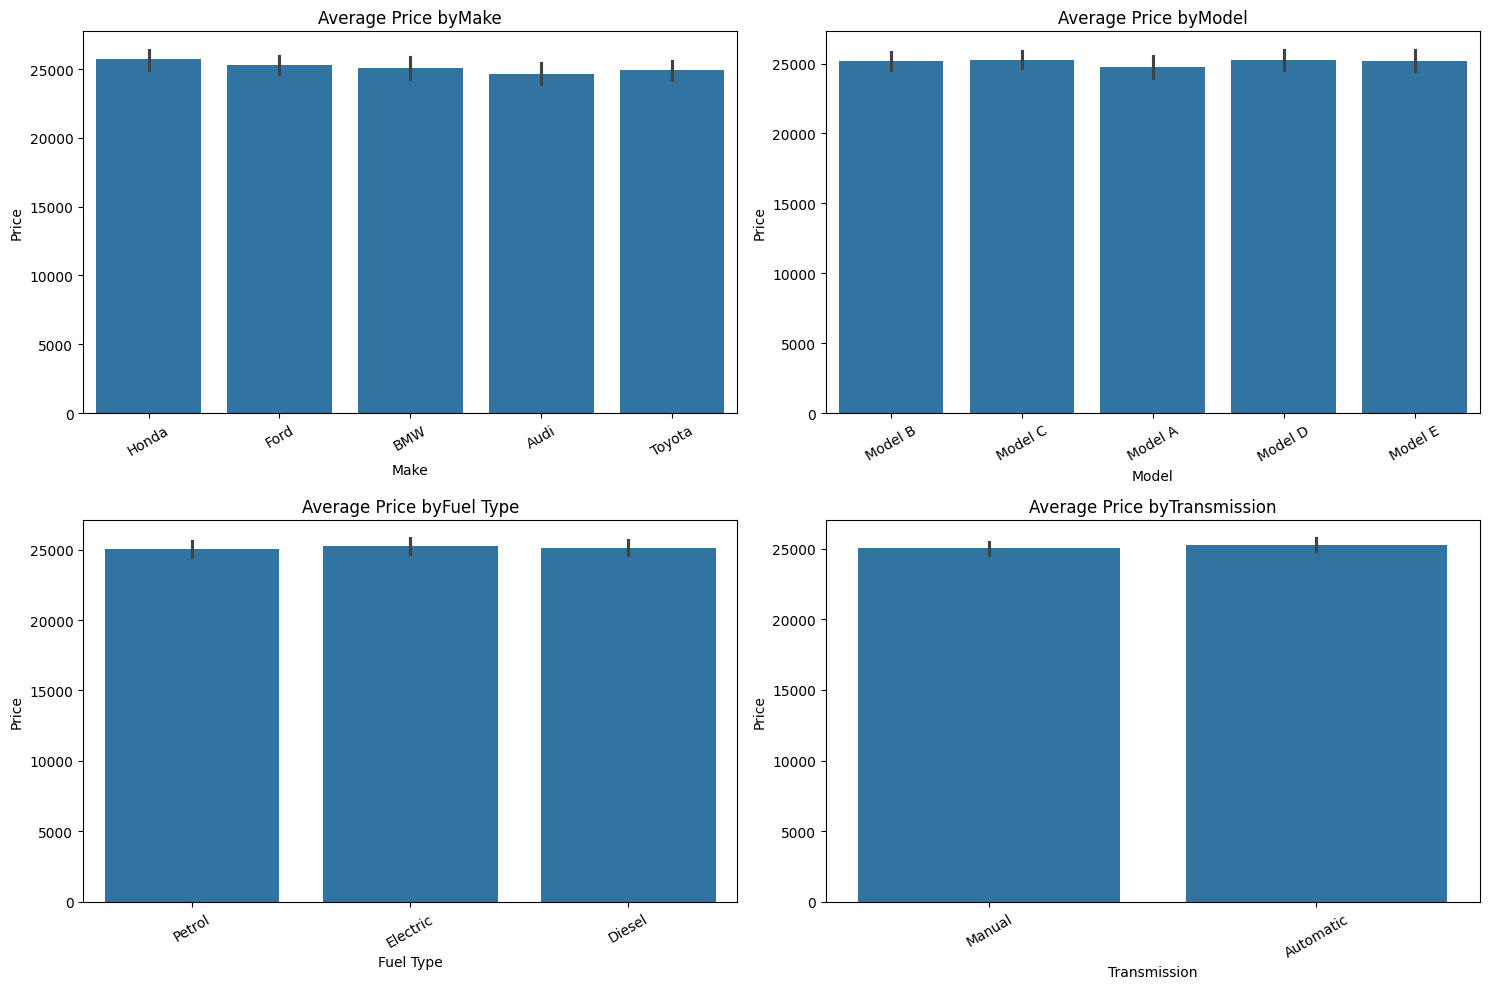

In [177]:
plt.figure(figsize=(15,10))

for index,col in enumerate(categorical_cols,1):
    plt.subplot(2,2,index)
    sns.barplot(data=df,x=col,y='Price')
    plt.title(f'Average Price by{col}')
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

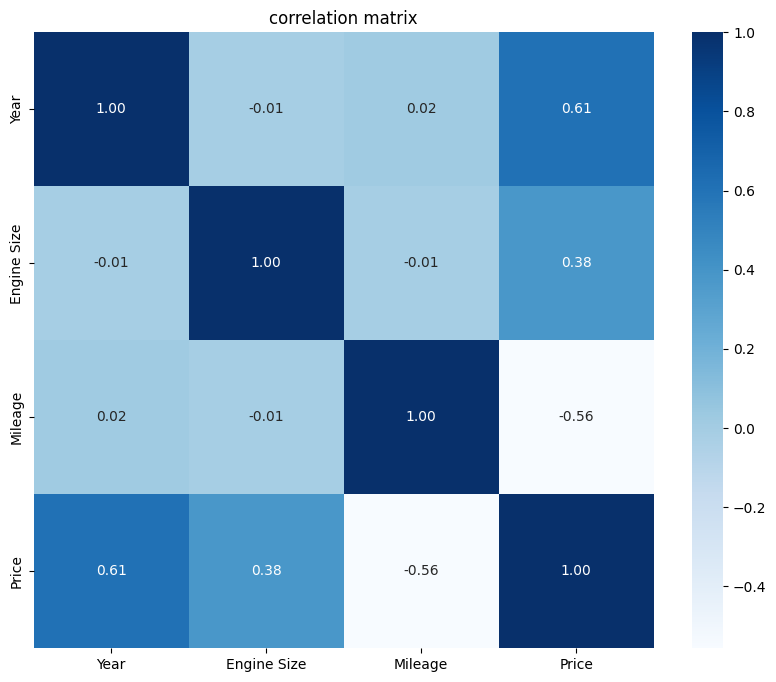

In [178]:
corr=df.select_dtypes(include='number').corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr,annot=True,cmap='Blues',fmt='.2f')
plt.title('correlation matrix')
plt.show()

In [179]:
df['Car Age']=2026-df['Year']
df[['Year','Car Age']].head()

,Year,Car Age
0,2015,11
1,2014,12
2,2006,20
3,2015,11
4,2004,22


In [180]:
x=df.drop(columns=['Price'])
y=df['Price']

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [181]:
cat_cols=x_train.select_dtypes(include='object').columns
encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
train_encoded=encoder.fit_transform(x_train[cat_cols])
test_encoded=encoder.transform(x_test[cat_cols])

In [182]:
cols_names=encoder.get_feature_names_out(cat_cols)
train_encoded=pd.DataFrame(train_encoded,columns=cols_names,index=x_train.index)
test_encoded=pd.DataFrame(test_encoded,columns=cols_names,index=x_test.index)

In [183]:
x_train=pd.concat([x_train,train_encoded],axis=1)
x_test=pd.concat([x_test,test_encoded],axis=1)

In [184]:
x_train=x_train.loc[:, ~x_train.columns.duplicated()]
x_test=x_test.loc[:, ~x_test.columns.duplicated()]

In [187]:
scaler=StandardScaler()
num_cols=['Engine Size','Mileage','Car Age']
x_train[num_cols]=scaler.fit_transform(x_train[num_cols])
x_test[num_cols]=scaler.transform(x_test[num_cols])

display(x_train.head())
display(x_test.head())

,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Car Age,Make_Audi,Make_BMW,...,Model_Model A,Model_Model B,Model_Model C,Model_Model D,Model_Model E,Fuel Type_Diesel,Fuel Type_Electric,Fuel Type_Petrol,Transmission_Automatic,Transmission_Manual
29,Honda,Model B,2001,0.089052,-1.378616,Electric,Automatic,1.582024,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
535,Audi,Model E,2007,-0.685311,1.549909,Electric,Automatic,0.617375,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
695,Audi,Model C,2012,0.089052,1.240727,Electric,Automatic,-0.186499,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
557,BMW,Model D,2004,-1.556469,-0.829569,Diesel,Automatic,1.099700,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
836,Ford,Model E,2020,0.960210,0.941258,Electric,Manual,-1.472697,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Car Age,Make_Audi,Make_BMW,...,Model_Model A,Model_Model B,Model_Model C,Model_Model D,Model_Model E,Fuel Type_Diesel,Fuel Type_Electric,Fuel Type_Petrol,Transmission_Automatic,Transmission_Manual
521,Audi,Model B,2008,-0.975697,-1.385905,Diesel,Manual,0.456600,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
737,Audi,Model E,2015,-0.007744,-0.808714,Petrol,Manual,-0.668823,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
740,BMW,Model C,2008,-0.588516,-1.509692,Electric,Automatic,0.456600,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
660,Audi,Model B,2018,0.379438,0.723948,Petrol,Automatic,-1.151148,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
411,BMW,Model E,2014,-0.394925,-0.641498,Electric,Automatic,-0.508048,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


In [188]:
print("X train shape:", x_train.shape)
print("Text columns:", x_train.select_dtypes(include='object').columns.tolist())

print("X test shape:", x_test.shape)
print("Text columns test:", x_test.select_dtypes(include='object').columns.tolist())

X train shape: (800, 23)
Text columns: ['Make', 'Model', 'Fuel Type', 'Transmission']
X test shape: (200, 23)
Text columns test: ['Make', 'Model', 'Fuel Type', 'Transmission']


In [186]:
lr=LinearRegression()
lr.fit(x_train,y_train)

ValueError: could not convert string to float: 'Honda'

In [121]:
y_train_pred=lr.predict(x_train)
print("Linear Regression - Training")
print("MSE:",mean_squared_error(y_train,y_train_pred))
print("MAE:",mean_absolute_error(y_train,y_train_pred))
print("R2 score:",r2_score(y_train,y_train_pred))

Linear Regression - Training
MSE: 4115430.251218587
MAE: 1599.7125244598346
R2 score: 0.8457629551700934


In [122]:
y_test_pred=lr.predict(x_test)
print("Linear Regression - Testing")
print("MSE:",mean_squared_error(y_test,y_test_pred))
print("MAE:",mean_absolute_error(y_test,y_test_pred))
print("R2 score:",r2_score(y_test,y_test_pred))

Linear Regression - Testing
MSE: 5005401.567585033
MAE: 1810.5593462730412
R2 score: 0.8170987263274687


In [123]:
sgd_model=SGDRegressor(loss="squared_error",max_iter=10000,learning_rate="constant",eta0=0.01,random_state=42)
sgd_model.fit(x_train,y_train)

SGDRegressor(learning_rate='constant', max_iter=10000, random_state=42)

In [124]:
y_train_pred_sgd=sgd_model.predict(x_train)
print("SGDRegressor - Training")
print("MSE:",mean_squared_error(y_train,y_train_pred_sgd))
print("MAE:",mean_absolute_error(y_train,y_train_pred_sgd))
print("R2 score:",r2_score(y_train,y_train_pred_sgd))

SGDRegressor - Training
MSE: 1.1541106975784083e+32
MAE: 1.0742900423724534e+16
R2 score: -4.3253466231961436e+24


In [125]:
y_test_pred_sgd=sgd_model.predict(x_test)
print("SGDRegressor - Testing")
print("MSE:",mean_squared_error(y_test,y_test_pred_sgd))
print("MAE:",mean_absolute_error(y_test,y_test_pred_sgd))
print("R2 score:",r2_score(y_test,y_test_pred_sgd))

SGDRegressor - Testing
MSE: 1.1532235168652681e+32
MAE: 1.0738764953066742e+16
R2 score: -4.2139685940430806e+24
